# Phase 3: failure modes, similar reports, early warnings

Question: can we tell *how* a device failed from a report, find reports like it, and spot a company's failure mode rising before a recall? Full write-up: [`docs/FAILURE_MODES.md`](../docs/FAILURE_MODES.md) (generated).

**Key ideas**
- **Codebook:** written definitions of each failure mode, fixed before labelling (`config/failure_modes.json`).
- **Reference labels:** 200 reports labelled from the codebook (by Claude; 18/20 agreed on a second full-text pass).
- **Validation vs test:** methods are compared and chosen on the validation half; the test half is scored once.
- **Embedding:** a list of numbers that places a text by meaning; similar texts get similar numbers.
- **Signal:** a month with far more reports than the previous year's average (Poisson rule), per company and mode.

In [1]:
import json, os, csv
from pathlib import Path
import numpy as np, pandas as pd, psycopg
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / '.env')
con = psycopg.connect(os.environ['DATABASE_URL'])
R = lambda n: json.loads((ROOT / 'results/phase3' / n).read_text(encoding='utf-8'))
SEL, RET, SIG, VER = R('selection.json'), R('retrieval.json'), R('signals.json'), R('verify_phase3.json')
pred = pd.read_csv(ROOT / 'results/phase3/predictions_sample.csv', dtype=str)
print('Scorecard:', VER['scorecard_score'])

Scorecard: 5/5


## 1. Five methods, chosen on validation, tested once

In [2]:
pd.DataFrame({m: {'setting': SEL['chosen_settings'][m], 'validation': SEL['validation_accuracy'][m],
                  'test': SEL['test'][m]['accuracy'], 'test 95% interval': SEL['test'][m]['accuracy_ci95'],
                  **{f'test {f}': v for f, v in SEL['test'][m]['accuracy_by_family'].items()}}
              for m in ['M1', 'M2', 'M3', 'M4', 'M5']}).T

,setting,validation,test,test 95% interval,test orthopedic,test cardiac,test diabetes
M1,M1,0.75,0.7,"[0.61, 0.79]",0.65,0.65,0.9
M2,M2:earliest,0.75,0.6,"[0.51, 0.69]",0.45,0.8,0.85
M3,M3:None,0.39,0.32,"[0.2398, 0.41]",0.1833,0.55,0.5
M4,M4:earliest+None,0.73,0.59,"[0.5, 0.68]",0.4333,0.8,0.85
M5,M5,0.51,0.35,"[0.26, 0.45]",0.2333,0.45,0.6


FDA's coded terms (M1) won: it tied the keyword rules on validation, won the tie-break as the simpler method, and was best on test. The expectation from Phase 1 (that the narrative would be needed) did not hold.

## 2. Where the chosen method goes wrong (test half)

In [3]:
t = pred[pred.split == 'test']
ct = pd.crosstab(t.label, t.M1, rownames=['reference'], colnames=['M1 predicted'])
ct.loc[:, ct.sum() > 0]

M1 predicted,C_BATTERY,C_INFECTION_POCKET,C_LEAD_CAPTURE,C_OTHER,C_SENSING,C_TELEMETRY_SOFTWARE,D_ADHESIVE_DISLODGED,D_ALARM_ELECTRONICS,D_CANNULA_INSERTION,D_LEAK,...,D_OTHER,D_SKIN,O_BONE_FRACTURE,O_DEVICE_FRACTURE,O_INFECTION,O_INSTABILITY,O_LOOSENING,O_OTHER,O_PAIN_STIFFNESS,O_WEAR
reference,,,,,,,,,,,,,,,,,,,,,
C_BATTERY,2,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C_INFECTION_POCKET,0,5,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C_LEAD_CAPTURE,1,0,3,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C_PREVENTIVE,1,0,0,4,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C_SENSING,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C_TELEMETRY_SOFTWARE,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D_ADHESIVE_DISLODGED,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D_ALARM_ELECTRONICS,0,0,0,0,0,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0
D_CANNULA_INSERTION,0,0,0,0,0,0,0,0,9,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Failure modes across all 154k reports

In [4]:
q = '''SELECT product_code, mode, count(*) n FROM analytics.report_failure_mode GROUP BY 1, 2'''
df = pd.DataFrame(con.execute(q).fetchall(), columns=['code', 'mode', 'n'])
df['share'] = (df.n / df.groupby('code').n.transform('sum')).round(3)
df.sort_values(['code', 'n'], ascending=[True, False]).groupby('code').head(4)

,code,mode,n,share
3,JWH,O_INSTABILITY,4676,0.166
1,JWH,O_DEVICE_FRACTURE,4342,0.154
2,JWH,O_INFECTION,4090,0.145
6,JWH,O_OTHER,3737,0.133
12,LPH,O_INSTABILITY,4267,0.263
11,LPH,O_INFECTION,3121,0.193
17,LPH,O_WEAR,2101,0.130
15,LPH,O_OTHER,1855,0.115
21,LWP,C_OTHER,11383,0.304
20,LWP,C_LEAD_CAPTURE,7673,0.205


## 4. Similar-report search, live

One insulin-pump report and its five nearest neighbours by embedding (cosine similarity). On the labelled test set, BM25 keyword search did slightly better (not significant). Note the similarities of 1.000: many manufacturer reports are word-for-word templates, so 'similar' often means 'identical wording'. Phase 4 should group identical texts and show the count instead of repeating them.

In [5]:
keys = (ROOT / 'data/processed/embeddings_bge_small_keys.txt').read_text().split()
E = np.load(ROOT / 'data/processed/embeddings_bge_small.npy').astype(np.float32)
row = {k: i for i, k in enumerate(keys)}
from mdqc.textprep import load_texts
q = '16005019'
same = [k for (k,) in con.execute("SELECT mdr_report_key FROM core.fact_report WHERE product_code='LZG'").fetchall()]
idx = np.array([row[k] for k in same]); sims = E[idx] @ E[row[q]]
top = [same[i] for i in np.argsort(-sims)[1:6]]
T = load_texts(con, 'core', [q] + top)
modes = dict(con.execute('SELECT mdr_report_key, mode FROM analytics.report_failure_mode WHERE mdr_report_key = ANY(%s)', ([q] + top,)).fetchall())
print('QUERY', q, modes[q], '|', T[q][:220])
for k in top: print(f'{float(E[row[k]] @ E[row[q]]):.3f}', k, modes[k], '|', T[k][:160])

QUERY 16005019 D_CANNULA_INSERTION | IT WAS REPORTED THAT THE NEEDLE DID NOT DEPLOY WHEN THE POD WAS ACTIVATED; THIS INDICATES THAT A NEEDLE MECHANISM FAILURE OCCURRED. THE POD WAS NOT WORN. || ACCORDING TO THE COMPLAINANT THE DEVICE WILL NOT BE RETURNED FO
1.000 16184719 D_CANNULA_INSERTION | IT WAS REPORTED THAT THE NEEDLE DID NOT DEPLOY WHEN THE POD WAS ACTIVATED; THIS INDICATES THAT A NEEDLE MECHANISM FAILURE OCCURRED. THE POD WAS NOT WORN. || ACC
1.000 16253961 D_CANNULA_INSERTION | IT WAS REPORTED THAT THE NEEDLE DID NOT DEPLOY WHEN THE POD WAS ACTIVATED; THIS INDICATES THAT A NEEDLE MECHANISM FAILURE OCCURRED. THE POD WAS NOT WORN. || ACC
1.000 16213619 D_CANNULA_INSERTION | IT WAS REPORTED THAT THE NEEDLE DID NOT DEPLOY WHEN THE POD WAS ACTIVATED; THIS INDICATES THAT A NEEDLE MECHANISM FAILURE OCCURRED. THE POD WAS NOT WORN. || ACC
1.000 16004920 D_CANNULA_INSERTION | IT WAS REPORTED THAT THE NEEDLE DID NOT DEPLOY WHEN THE POD WAS ACTIVATED; THIS INDICATES THAT A NEEDLE MECHANI

## 5. Early-warning signals and the recall backtest

In [6]:
print({k: SIG[k] for k in ['signals', 'signals_per_year', 'series_with_signal', 'series', 'recall_events', 'hits', 'hit_rate', 'base_rate']})
pd.DataFrame(SIG['events'])[['event', 'code', 'parent', 'initiated', 'hit']].head(12)

{'signals': 214, 'signals_per_year': 107.0, 'series_with_signal': 91, 'series': 475, 'recall_events': 38, 'hits': 15, 'hit_rate': 0.3947, 'base_rate': 0.1404}


,event,code,parent,initiated,hit
0,91842,LPH,ZIMMER BIOMET,2023-02-27,True
1,91866,LPH,ZIMMER BIOMET,2023-02-06,True
2,91906,MBH,ENCORE MEDICAL,2023-02-28,False
3,92257,MBH,STRYKER,2023-04-13,False
4,92294,JWH,LINKBIO,2023-04-25,False
5,92531,JWH,ZIMMER BIOMET,2023-05-19,True
6,92621,JWH,MATERIALISE N V,2023-04-26,False
7,92807,LPH,WALDEMAR LINK GMBH & CO KG MFG SITE,2023-07-14,False
8,92969,JWH,ENCORE MEDICAL,2023-08-04,False
9,92976,JWH,SMITH & NEPHEW,2023-08-31,True


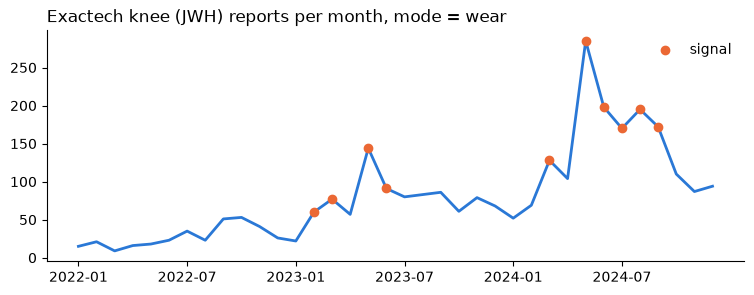

In [7]:
q = '''SELECT to_char(r.date_received, 'YYYY-MM') m, count(*) FROM core.fact_report r
        JOIN core.dim_manufacturer d USING (manufacturer_id) JOIN analytics.report_failure_mode f USING (mdr_report_key)
        WHERE r.product_code = 'JWH' AND d.parent_company = 'EXACTECH' AND f.mode = 'O_WEAR' GROUP BY 1 ORDER BY 1'''
s = pd.DataFrame(con.execute(q).fetchall(), columns=['month', 'n']).set_index('month').n
flag = [x['month'] for x in SIG['signal_list'] if x['code'] == 'JWH' and x['parent'] == 'EXACTECH' and x['mode'] == 'O_WEAR']
fig, ax = plt.subplots(figsize=(9, 3)); ax.plot(range(len(s)), s.values, color='#2a78d6', lw=2)
ax.scatter([list(s.index).index(m) for m in flag if m in s.index], [s[m] for m in flag if m in s.index], color='#eb6834', zorder=3, label='signal')
ax.set_xticks(range(0, len(s), 6), s.index[::6]); ax.set_title('Exactech knee (JWH) reports per month, mode = wear', loc='left')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False); plt.show()

A signal is a prompt to look, not evidence of a defect: reports also rise after recalls, lawsuits and retrospective reporting campaigns.

In [8]:
con.close()
pd.DataFrame([(c['id'], c['check'], 'pass' if c['pass'] else 'FAIL') for c in VER['checks']], columns=['id', 'check', 'result'])

,id,check,result
0,F1,criteria -> labels -> results committed in tha...,pass
1,F2,spot-check of 20 labels: >= 16 agree (reviewer...,pass
2,F3,chosen method and settings follow from validat...,pass
3,F4,"test accuracy, macro-F1, intervals and chosen-...",pass
4,F7,every report has one mode; DB = saved predicti...,pass
5,F5,retrieval rankings and MRR recomputed with own...,pass
6,F6,signals and backtest recomputed from the datab...,pass
7,F8,Phase 3 unit tests pass (CI runs them plus the...,pass


## Why we did these tasks

| Task | Why we did it | What we learned | What it changes next |
|---|---|---|---|
| Codebook before labels, labels before methods | So neither the labels nor the methods could drift toward the other | Writing definitions first forces hard choices (cause vs symptom, priority order) | Phase 6 reuses the same labels to grade the assistant |
| Five methods, chosen on validation, tested once | To learn whether anything beats FDA's own coded terms, without fooling ourselves | FDA terms mapped through the codebook won (70% on test); zero-shot embeddings failed | Phase 4's failure-mode tool uses the FDA-term mapping |
| Local embedding model | Meaning-based search for free on a laptop | 154k reports embedded on CPU in about 2.4 hours; embedding and BM25 search are close | Phase 4 offers similar-report search at no cost |
| Alert rule per company and mode, backtested | A quality engineer wants early warning, not hindsight | 15 of 38 recall events had a prior signal vs a 14% base rate | Phase 7 monitoring reuses the rule; the assistant presents signals as prompts, not proof |
| Independent verifier and 5-item scorecard | Every number recomputed by separate code | Scorecard 5/5; the full-corpus labels reproduced exactly | Same pattern for the assistant's evaluation in Phase 6 |